## 1. Import Libraries

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


## 2. Load Dataset

In [49]:


df = pd.read_csv('/content/Iris.csv')

df.head()


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 3. Basic Dataset Understanding

In [50]:

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types and non-null values:")
df.info()


Shape: (150, 6)

Columns:
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [51]:
df.describe()


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


## 4. Missing-Value Analysis


Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


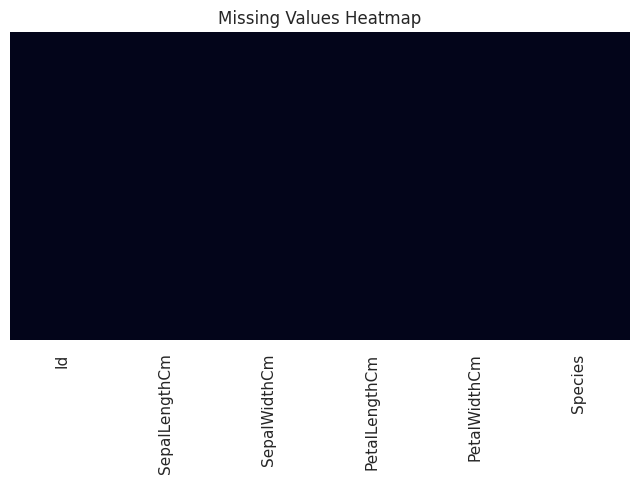

In [52]:
missing_values = df.isnull().sum()
print(missing_values)

plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values Heatmap")
plt.show()


## 5. Feature Selection for EDA

In [53]:
features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]


## 6. Distribution Analysis

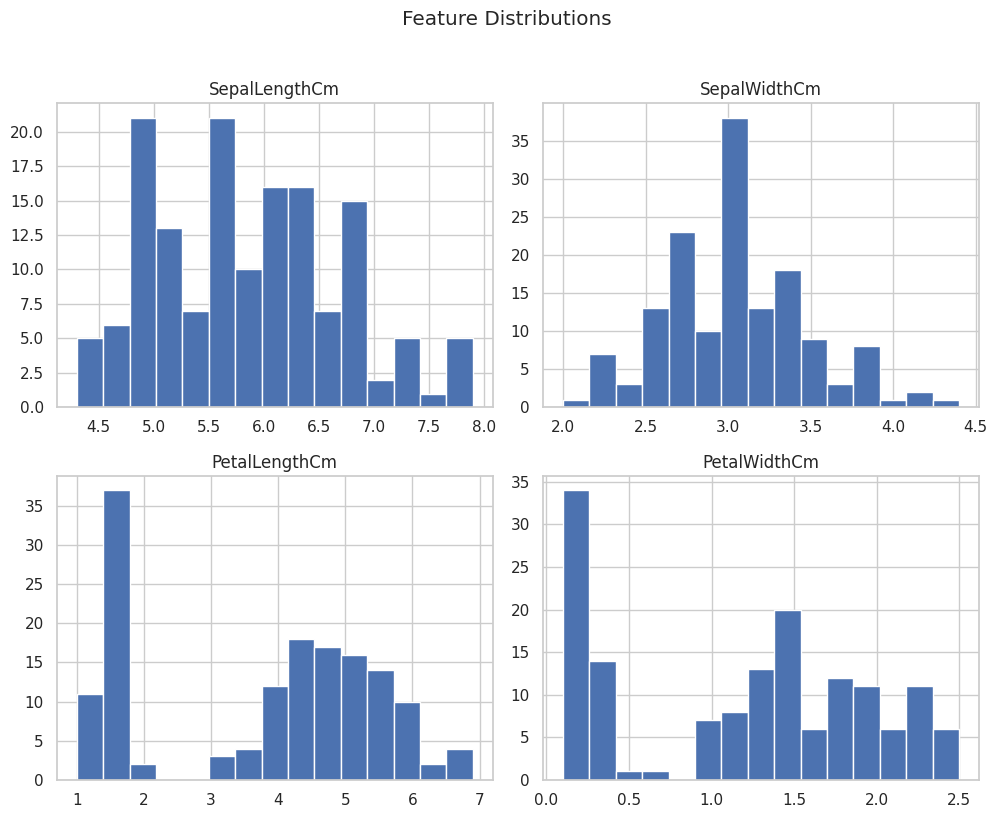

In [31]:
df[features].hist(figsize=(10, 8), bins=15)
plt.suptitle("Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()


## 7. Species/Class Distribution

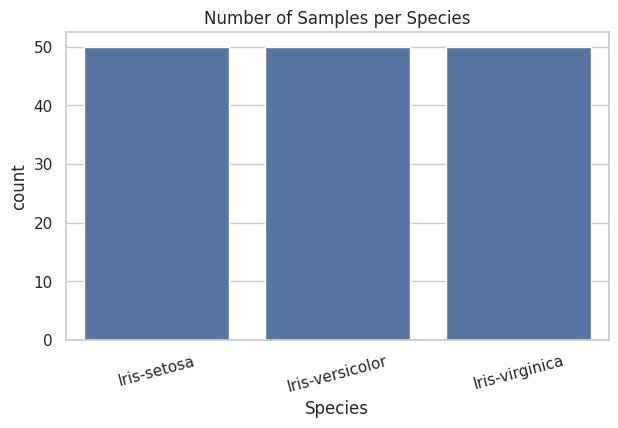

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [32]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Species")
plt.title("Number of Samples per Species")
plt.xticks(rotation=15)
plt.show()

print(df["Species"].value_counts())


## 8. Feature Relationships

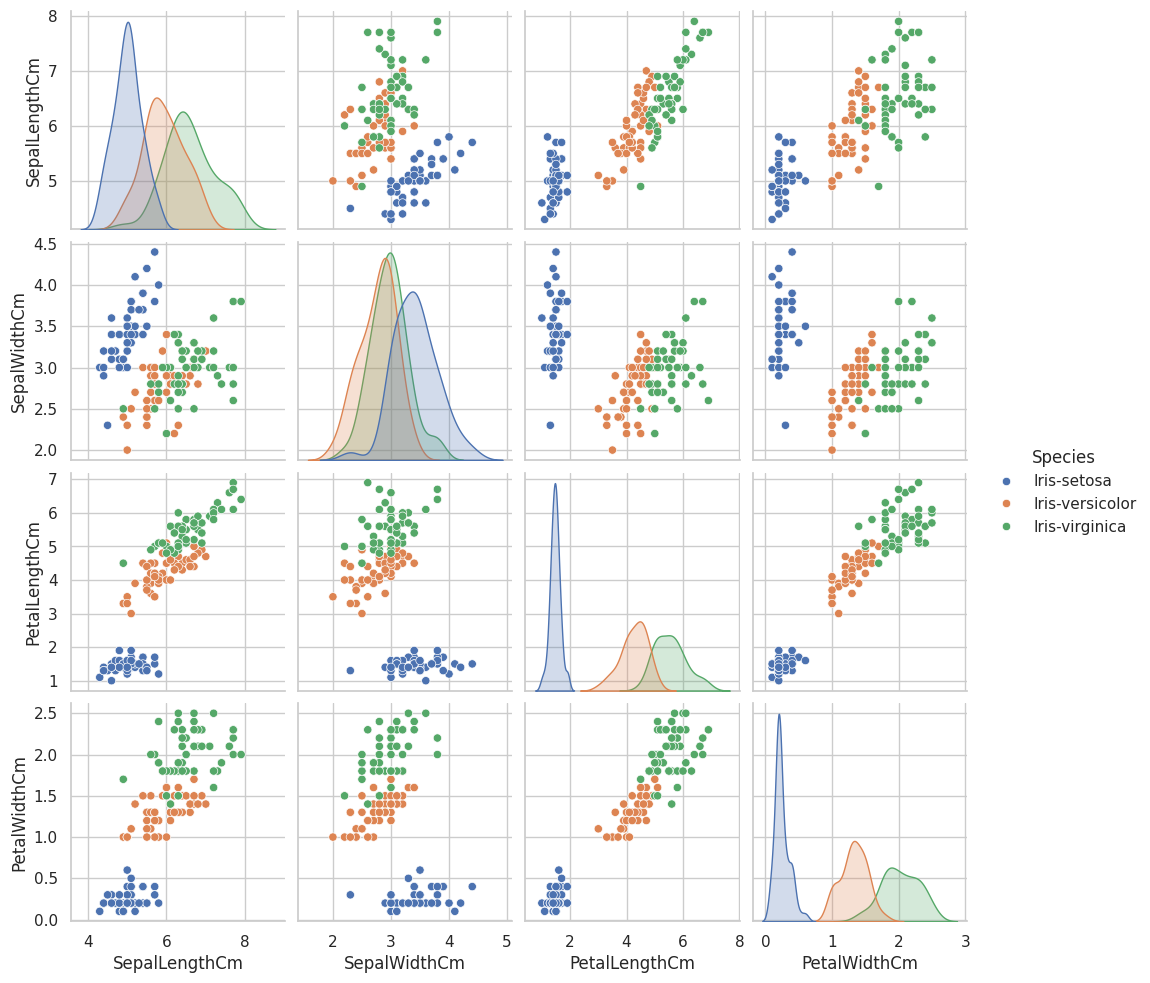

In [33]:
sns.pairplot(df[features + ["Species"]], hue="Species")
plt.show()


## 9. Correlation Analysis

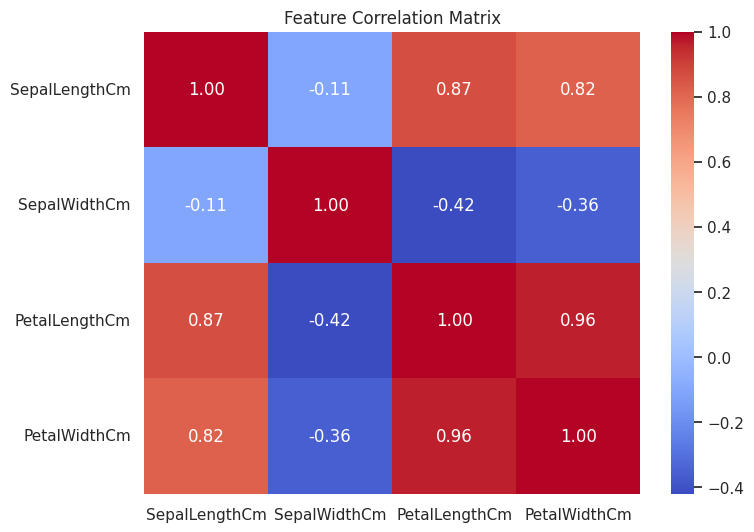

In [34]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    df[features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Feature Correlation Matrix")
plt.show()


## 10. Outlier Analysis Using IQR

In [35]:
outlier_summary = []

for column in features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    count = ((df[column] < lower_bound) | (df[column] > upper_bound)).sum()

    outlier_summary.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": count
    })

outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,SepalLengthCm,5.1,6.4,1.3,3.15,8.35,0
1,SepalWidthCm,2.8,3.3,0.5,2.05,4.05,4
2,PetalLengthCm,1.6,5.1,3.5,-3.65,10.35,0
3,PetalWidthCm,0.3,1.8,1.5,-1.95,4.05,0


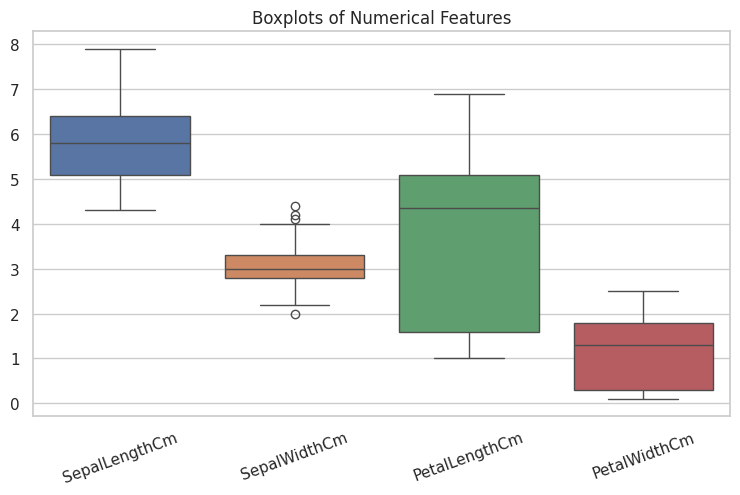

In [36]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df[features])
plt.title("Boxplots of Numerical Features")
plt.xticks(rotation=20)
plt.show()


## 11. Encode the Target

In [37]:
label_encoder = LabelEncoder()

df["Species"] = label_encoder.fit_transform(df["Species"])

print("Encoded classes:")
for label, class_name in enumerate(label_encoder.classes_):
    print(f"{class_name} -> {label}")

df.head()


Encoded classes:
Iris-setosa -> 0
Iris-versicolor -> 1
Iris-virginica -> 2


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,0
1,2,4.9,3.0,1.4,0.2,0
2,3,4.7,3.2,1.3,0.2,0
3,4,4.6,3.1,1.5,0.2,0
4,5,5.0,3.6,1.4,0.2,0


## 12. Separate Features and Target

In [38]:
X = df.drop(columns=["Id", "Species"])
y = df["Species"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)


Feature shape: (150, 4)
Target shape: (150,)


## 13. Train-Test Split

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 120
Testing samples: 30


## 14. Logistic Regression

In [40]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)

logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

print(f"Logistic Regression Accuracy: {logistic_accuracy:.4f}")


Logistic Regression Accuracy: 0.9333


### Logistic Regression Classification Report

In [41]:
print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=label_encoder.classes_
    )
)


                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



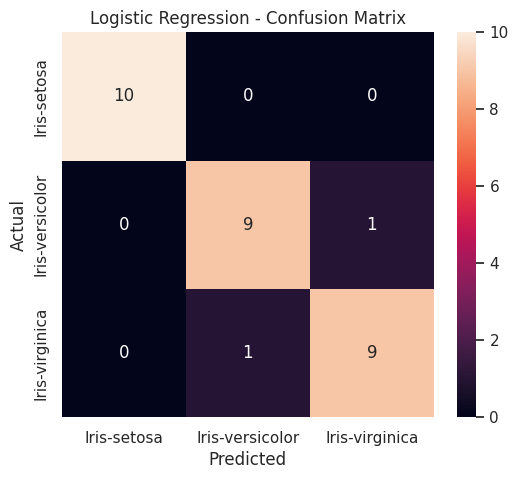

In [42]:
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


## 15. K-Nearest Neighbors (KNN)

In [43]:
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

knn_accuracy = accuracy_score(y_test, y_pred_knn)

print(f"KNN Accuracy (k=5): {knn_accuracy:.4f}")


KNN Accuracy (k=5): 0.9333


### KNN Classification Report

In [44]:
print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=label_encoder.classes_
    )
)


                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



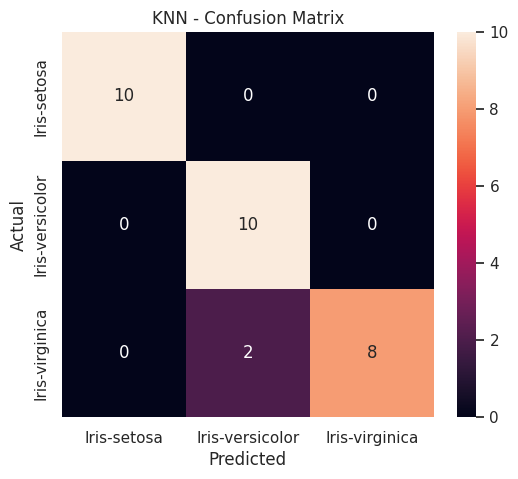

In [45]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN - Confusion Matrix")
plt.show()


## 16. KNN Hyperparameter Check

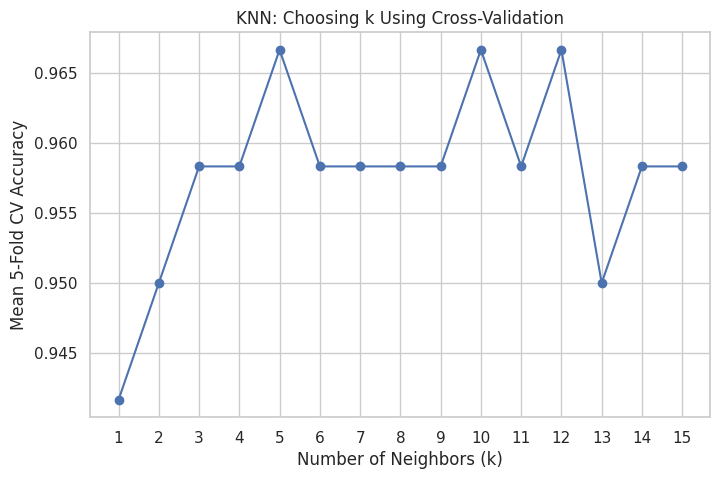

Best k based on training-set 5-fold CV: 5


In [46]:
k_values = range(1, 16)
k_scores = []

for k in k_values:
    knn = Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_val_score(
        knn,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    k_scores.append(scores.mean())

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), k_scores, marker="o")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean 5-Fold CV Accuracy")
plt.title("KNN: Choosing k Using Cross-Validation")
plt.xticks(list(k_values))
plt.show()

best_k = list(k_values)[k_scores.index(max(k_scores))]
print(f"Best k based on training-set 5-fold CV: {best_k}")


## 17. Model Comparison

In [47]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN (k=5)"],
    "Test Accuracy": [logistic_accuracy, knn_accuracy]
})

comparison


,Model,Test Accuracy
0,Logistic Regression,0.933333
1,KNN (k=5),0.933333


## 18. Final Evaluation Summary

In [48]:
print("===== FINAL RESULTS =====")
print(f"Logistic Regression Test Accuracy: {logistic_accuracy:.4f}")
print(f"KNN (k=5) Test Accuracy:          {knn_accuracy:.4f}")
print(f"Best KNN k from CV:               {best_k}")


===== FINAL RESULTS =====
Logistic Regression Test Accuracy: 0.9333
KNN (k=5) Test Accuracy:          0.9333
Best KNN k from CV:               5
